### 1. 概述

启用 **`Checkpointer`** 后，**`LangGraph`** 会在执行过程中保存检查点。

检查点写入**越及时**，系统在异常中断后可恢复的状态**越完整**，**容灾能力越强**；但更及时的持久化通常也意味着**更多中间写入**，或**额外的**阻塞式**等待**，带来**额外的性能开销和响应延迟**（从调用者的角度考虑）。

**`LangGraph`** 支持三种持久化模式，采用不同的检查点保存时机，在容灾能力和性能开销、响应时效性之间作取舍。

- **`exit`**：退出模式。只在计算图正常结束、异常退出、被中断（如 **`Human-In-The-Loop`** 中断）时保存检查点。**不能处理中途进程崩溃的场景**。这种模式响应性能开销最小，但容灾能力最弱。

- **`async`**：异步模式。默认模式，顾名思义，检查点在后台异步写入。

  它会在每个超步结束后写入**完整检查点（主检查点）**，并在图中任务执行完毕后记录**中间结果**。

  和 **`exit`** 模式相比，增加了性能开销，但写入操作发生在后台，不会引入明显的响应延迟，同时提升了容灾能力。

- **`sync`**：同步模式。

  和异步模式唯一的区别在于，**`LangGraph`** 会在进入下一个超步之前等待当前主检查点的写入任务完成。

  它的容灾能力最强，但在 **`async`** 模式的基础上增加了响应延迟。

**总结**

| 模式        | 写入时机                                                     | 性能开销 | 响应延迟 | 容灾能力 |
| ----------- | ------------------------------------------------------------ | -------- | -------- | -------- |
| **`exit`**  | 运行退出时写入                                               | 低       | 最低     | 最弱     |
| **`async`** | 每个超步末尾写入主检查点，任务完成后写入中间结果，后台异步写入 | 高       | 较高     | 较强     |
| **`sync`**  | 和 **`async`** 区别在于，进入下一个超步之前等待当前主检查点的写入任务完成 | 高       | 最高     | 最强     |

你好！很高兴和你交流。请问今天有什么我可以帮你的吗？
============================== -> 完整消息列表 <- ==============================
================================ Human Message =================================

你好
================================== Ai Message ==================================

你好！很高兴和你交流。请问今天有什么我可以帮你的吗？


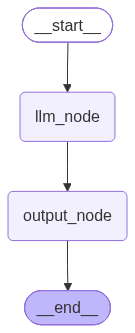

In [3]:
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from dotenv import load_dotenv
from langgraph.config import RunnableConfig
from IPython.display import display

import os

load_dotenv(override=True)

qwen_model = init_chat_model(
    model="qwen3.7-flash",
    model_provider="openai",
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url=os.getenv("DASHSCOPE_BASE_URL"),
)

class OverAllState(MessagesState):
    output: str

def llm_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    res = qwen_model.invoke(messages)
    return {
        "messages": [res],
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "output": state["messages"][-1].content,
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("llm_node", llm_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", "output_node")
builder.add_edge("output_node", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

myconfig: RunnableConfig = RunnableConfig(
    configurable = {
        "thread_id": "thread_001"
    }
)

resp = graph.invoke(
    {
        "messages": [HumanMessage("你好")],
    },
    config=myconfig,
    durability="async"
)
print(resp["output"])

print("="* 30, "-> 完整消息列表 <-", "=" * 30)
for msg in resp["messages"]:
    msg.pretty_print()

display(graph)

2. 查看完整历史检查点列表

2026-10-21 20:55:37.260 | INFO     | __main__:node_joke:45 - node_joke 已经执行
2026-10-21 20:55:37.263 | INFO     | __main__:node_poem:35 - node_poem 已经执行
2026-10-21 20:56:27.774 | INFO     | __main__:node_output:55 - node_output 已经执行


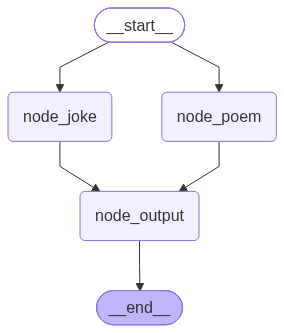

============================== -> 运行结果 <- ==============================


{
    'final_output': 
'关于小猫的七言绝句：\n《咏狸奴》\n巧爪轻探逗彩丝，\n偷眠暖日透疏篱。\n忽惊黄蝶翩跹过，\n跃上青砖逐影移。\n\n注：本
诗押平水韵上平四支（丝、篱、移），依七绝仄起首句入韵正格。以“探丝—眠日—惊蝶—逐影”四笔勾勒小猫机敏慵懒之态，动静相生
，合乎绝句起承转合之法。\n笑话：**《小猫的KPI》**\n\n问：为什么小猫总爱把桌上的水杯推下去？\n\n答：因为它在完成一项
秘密考核。\n第一次推，你在叹气；\n第二次推，你在举手警告；\n第三次推，你已经跪在地毯上喊“祖宗别碰”。\n\n小猫端坐一
旁，尾巴轻轻一扫：“压力测试通过。两脚兽的反应阈值符合预期，本喵今日KPI达标。”\n\n说完打了个哈欠，补了一句：\n“所以…
…罐头可以兑现了吧？” 🐾'
}

============================== -> 历史检查点列表 <- ==============================


[
    StateSnapshot(
        values={
            'topic': '小猫',
            'poem': 
'《咏狸奴》\n巧爪轻探逗彩丝，\n偷眠暖日透疏篱。\n忽惊黄蝶翩跹过，\n跃上青砖逐影移。\n\n注：本诗押平水韵上平四支（丝
、篱、移），依七绝仄起首句入韵正格。以“探丝—眠日—惊蝶—逐影”四笔勾勒小猫机敏慵懒之态，动静相生，合乎绝句起承转合之法
。',
            'joke': 
'**《小猫的KPI》**\n\n问：为什么小猫总爱把桌上的水杯推下去？\n\n答：因为它在完成一项秘密考核。\n第一次推，你在叹气
；\n第二次推，你在举手警告；\n第三次推，你已经跪在地毯上喊“祖宗别碰”。\n\n小猫端坐一旁，尾巴轻轻一扫：“压力测试通过
。两脚兽的反应阈值符合预期，本喵今日KPI达标。”\n\n说完打了个哈欠，补了一句：\n“所以……罐头可以兑现了吧？” 🐾',
            'final_output': 
'关于小猫的七言绝句：\n《咏狸奴》\n巧爪轻探逗彩丝，\n偷眠暖日透疏篱。\n忽惊黄蝶翩跹过，\n跃上青砖逐影移。\n\n注：本
诗押平水韵上平四支（丝、篱、移），依七绝仄起首句入韵正格。以“探丝—眠日—惊蝶—逐影”四笔勾勒小猫机敏慵懒之态，动静相生
，合乎绝句起承转合之法。\n笑话：**《小猫的KPI》**\n\n问：为什么小猫总爱把桌上的水杯推下去？\n\n答：因为它在完成一项
秘密考核。\n第一次推，你在叹气；\n第二次推，你在举手警告；\n第三次推，你已经跪在地毯上喊“祖宗别碰”。\n\n小猫端坐一
旁，尾巴轻轻一扫：“压力测试通过。两脚兽的反应阈值符合预期，本喵今日KPI达标。”\n\n说完打了个哈欠，补了一句：\n“所以…
…罐头可以兑现了吧？” 🐾'
        },
        next=(),
        config={
            'configurable': {
                'thread_id': 'thread_001',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd4ed-446e-6958-8002-fc4f9f6693c2'
            }
        },
        metadata={'source': 'loop', 'step': 2, 'parents': {}},
        created_at='2026-10-21T12:56:27.775624+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'thread_001',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd4ed-446a-6f32-8001-c0bb50ca420a'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={
            'topic': '小猫',
            'poem': 
'《咏狸奴》\n巧爪轻探逗彩丝，\n偷眠暖日透疏篱。\n忽惊黄蝶翩跹过，\n跃上青砖逐影移。\n\n注：本诗押平水韵上平四支（丝
、篱、移），依七绝仄起首句入韵正格。以“探丝—眠日—惊蝶—逐影”四笔勾勒小猫机敏慵懒之态，动静相生，合乎绝句起承转合之法
。',
            'joke': 
'**《小猫的KPI》**\n\n问：为什么小猫总爱把桌上的水杯推下去？\n\n答：因为它在完成一项秘密考核。\n第一次推，你在叹气
；\n第二次推，你在举手警告；\n第三次推，你已经跪在地毯上喊“祖宗别碰”。\n\n小猫端坐一旁，尾巴轻轻一扫：“压力测试通过
。两脚兽的反应阈值符合预期，本喵今日KPI达标。”\n\n说完打了个哈欠，补了一句：\n“所以……罐头可以兑现了吧？” 🐾'
        },
        next=('node_output',),
        config={
            'configurable': {
                'thread_id': 'thread_001',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd4ed-446a-6f32-8001-c0bb50ca420a'
            }
        },
        metadata={'source': 'loop', 'step': 1, 'parents': {}},
        created_at='2026-10-21T12:56:27.774136+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'thread_001',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd4eb-62ac-66be-8000-3799036284b9'
            }
        },
        tasks=(
            PregelTask(
                id='d811efd1-5c4c-0d1f-36f7-617e8affac85',
                name='node_output',
                path=('__pregel_pull', 'node_output'),
                error=None,
                interrupts=(),
                state=None,
                result={
                    'final_output': 
'关于小猫的七言绝句：\n《咏狸奴》\n巧爪轻探逗彩丝，\n偷眠暖日透疏篱。\n忽惊黄蝶翩跹过，\n跃上青砖逐影移。\n\n注：本
诗押平水韵上平四支（丝、篱、移），依七绝仄起首句入韵正格。以“探丝—眠日—惊蝶—逐影”四笔勾勒小猫机敏慵懒之态，动静相生
，合乎绝句起承转合之法。\n笑话：**《小猫的KPI》**\n\n问：为什么小猫总爱把桌上的水杯推下去？\n\n答：因为它在完成一项
秘密考核。\n第一次推，你在叹气；\n第二次推，你在举手警告；\n第三次推，你已经跪在地毯上喊“祖宗别碰”。\n\n小猫端坐一
旁，尾巴轻轻一扫：“压力测试通过。两脚兽的反应阈值符合预期，本喵今日KPI达标。”\n\n说完打了个哈欠，补了一句：\n“所以…
…罐头可以兑现了吧？” 🐾'
                }
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={'topic': '小猫'},
        next=('node_poem', 'node_joke'),
        config={
            'configurable': {
                'thread_id': 'thread_001',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd4eb-62ac-66be-8000-3799036284b9'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-21T12:55:37.259590+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'thread_001',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd4eb-62a9-6ffe-bfff-c73a51f45609'
            }
        },
        tasks=(
            PregelTask(
                id='dee9ad1b-04a9-c420-8819-17818a11f1

In [7]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.config import RunnableConfig
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from loguru import logger
from dotenv import load_dotenv
from IPython.display import display
from rich import print as rprint
import os

load_dotenv(override=True)

qwen_model = init_chat_model(
    model="qwen3.7-flash",
    model_provider="openai",
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url=os.getenv("DASHSCOPE_BASE_URL"),
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    final_output: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    final_output: str

def node_poem(state: InputState) -> OverAllState:
    logger.info(f"node_poem 已经执行")
    topic = state["topic"]
    poem = qwen_model.invoke(
        [HumanMessage(f"写一首关于{topic}的七言绝句")],
    ).content
    return {
        "poem": poem,
    }

def node_joke(state: InputState) -> OverAllState:
    logger.info(f"node_joke 已经执行")
    topic = state["topic"]
    joke = qwen_model.invoke(
        [HumanMessage(f"写一个关于{topic}的笑话")]
    ).content
    return {
        "joke": joke,
    }

def node_output(state: OverAllState) -> OutputState:
    logger.info("node_output 已经执行")
    topic = state["topic"]
    poem = state["poem"]
    joke = state["joke"]
    final_output = f"关于{topic}的七言绝句：\n{poem}\n笑话：{joke}"
    return {
        "final_output": final_output,
    }

builder = StateGraph(
    state_schema=OverAllState,
    input_schema=InputState,
    output_schema=OutputState,
)
builder.add_node("node_poem", node_poem)
builder.add_node("node_joke", node_joke)
builder.add_node("node_output", node_output)

builder.add_edge(START, "node_poem")
builder.add_edge(START, "node_joke")
builder.add_edge("node_poem", "node_output")
builder.add_edge("node_joke", "node_output")
builder.add_edge("node_output", END)

checkpointer = InMemorySaver()
myconfig: RunnableConfig = RunnableConfig(
    configurable = {
        "thread_id": "thread_001"
    }
)
graph = builder.compile(checkpointer=checkpointer)
resp = graph.invoke({
    "topic": "小猫"
}, config=myconfig)

display(graph)

print('=' * 30, '-> 运行结果 <-', '=' * 30)
rprint(resp)

print('=' * 30, '-> 历史检查点列表 <-', '=' * 30)
# 从最新的到最旧的，依次检查
history_checkpoints = list(graph.get_state_history(config=myconfig))
rprint(history_checkpoints)

3. 查看最新检查点

2026-10-21 21:42:05.638 | INFO     | __main__:node_joke:43 - node_joke 已执行
2026-10-21 21:42:05.640 | INFO     | __main__:node_poem:35 - node_poem 已执行
2026-10-21 21:43:22.111 | INFO     | __main__:node_output:51 - node_output 已经执行


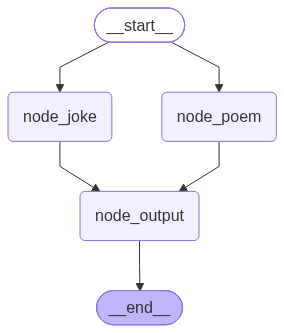

============================== -> 运行结果 <- ==============================


{
    'final_output': '关于 小猫 
的七言绝句：\n娇憨乍试步轻柔，\n扑蝶追风过小楼。\n忽散绒球穿竹径，\n归来静卧暖毡裘。\n笑话：\n问：小猫为什么从不参
加辩论赛？\n答：因为它们只会“喵”，而且一着急就炸毛！'
}

============================== -> 最新历史检查点 <- ==============================


StateSnapshot(
    values={
        'topic': '小猫',
        'poem': '娇憨乍试步轻柔，\n扑蝶追风过小楼。\n忽散绒球穿竹径，\n归来静卧暖毡裘。',
        'joke': '问：小猫为什么从不参加辩论赛？\n答：因为它们只会“喵”，而且一着急就炸毛！',
        'final_output': '关于 小猫 
的七言绝句：\n娇憨乍试步轻柔，\n扑蝶追风过小楼。\n忽散绒球穿竹径，\n归来静卧暖毡裘。\n笑话：\n问：小猫为什么从不参
加辩论赛？\n答：因为它们只会“喵”，而且一着急就炸毛！'
    },
    next=(),
    config={
        'configurable': {
            'thread_id': 'thread_001',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1cd556-1c09-6b0f-8002-29e121de0c6e'
        }
    },
    metadata={'source': 'loop', 'step': 2, 'parents': {}},
    created_at='2026-10-21T13:43:22.112283+00:00',
    parent_config={
        'configurable': {
            'thread_id': 'thread_001',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1cd556-1c07-6447-8001-5723fb582819'
        }
    },
    tasks=(),
    interrupts=()
)

In [8]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.config import RunnableConfig
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from loguru import logger
from dotenv import load_dotenv
from IPython.display import display
from rich import print as rprint
import os

load_dotenv(override=True)

qwen_model = init_chat_model(
    model="qwen3.7-flash",
    model_provider="openai",
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url=os.getenv("DASHSCOPE_BASE_URL"),
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    final_output: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    final_output: str

def node_poem(state: InputState) -> OverAllState:
    logger.info(f"node_poem 已执行")
    topic = state["topic"]
    poem = qwen_model.invoke([HumanMessage(f"写一首关于 {topic} 的七言绝句，不要赏析，只给诗句即可")]).content
    return {
        "poem": poem
    }

def node_joke(state: InputState) -> OverAllState:
    logger.info(f"node_joke 已执行")
    topic = state["topic"]
    joke = qwen_model.invoke([HumanMessage(f"写一个关于 {topic} 的笑话，尽可能简单，不超过一百字")]).content
    return {
        "joke": joke
    }

def node_output(state: OverAllState) -> OutputState:
    logger.info("node_output 已经执行")
    topic = state["topic"]
    poem = state["poem"]
    joke = state["joke"]
    final_output = f"关于 {topic} 的七言绝句：\n{poem}\n笑话：\n{joke}"
    return {
        "final_output": final_output,
    }

builder = StateGraph(
    state_schema=OverAllState,
    input_schema=InputState,
    output_schema=OutputState,
)
builder.add_node("node_poem", node_poem)
builder.add_node("node_joke", node_joke)
builder.add_node("node_output", node_output)

builder.add_edge(START, "node_poem")
builder.add_edge(START, "node_joke")
builder.add_edge("node_poem", "node_output")
builder.add_edge("node_joke", "node_output")
builder.add_edge("node_output", END)

checkpointer = InMemorySaver()
myconfig: RunnableConfig = RunnableConfig(
    configurable = {
        "thread_id": "thread_001"
    }
)
graph = builder.compile(checkpointer=checkpointer)
resp = graph.invoke({
    "topic": "小猫"
}, config=myconfig)

display(graph)

print('=' * 30, '-> 运行结果 <-', '=' * 30)
rprint(resp)

print('=' * 30, '-> 最新历史检查点 <-', '=' * 30)
latest_history_checkpoint = graph.get_state(config=myconfig)
rprint(latest_history_checkpoint)